# Análisis exploratorio - House Pricing

**Autor:** Roberto Farfan

Exploración inicial del dataset de precios de casas.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from house_pricing.config import FIGURES_DIR, RAW_DATA_DIR

2026-10-28 15:42:22.545 | INFO     | house_pricing.config:<module>:11 - PROJ_ROOT path is: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Ejercicios Clase\House_Pricing


## Carga de datos

In [3]:
train = pd.read_csv(RAW_DATA_DIR / "train.csv")
test = pd.read_csv(RAW_DATA_DIR / "test.csv")

print(f"train: {train.shape} | test: {test.shape}")

# El análisis exploratorio se hace sobre train, que es el único que incluye SalePrice
df = train
df.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Estructura y tipos de datos

In [4]:
print(df.shape)
df.info()

(1460, 81)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## Estadísticas descriptivas

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1460.0,NaN,NaN,NaN,730.5,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,NaN,NaN,NaN,56.89726,42.300571,20.0,20.0,50.0,70.0,190.0
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,1201.0,NaN,NaN,NaN,70.049958,24.284752,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,NaN,NaN,NaN,10516.828082,9981.264932,1300.0,7553.5,9478.5,11601.5,215245.0
...,...,...,...,...,...,...,...,...,...,...,...
MoSold,1460.0,NaN,NaN,NaN,6.321918,2.703626,1.0,5.0,6.0,8.0,12.0
YrSold,1460.0,NaN,NaN,NaN,2007.815753,1.328095,2006.0,2007.0,2008.0,2009.0,2010.0
SaleType,1460,9,WD,1267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SaleCondition,1460,6,Normal,1198,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Valores faltantes

In [6]:
faltantes = df.isna().sum()
faltantes[faltantes > 0].sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

## Distribuciones de variables numéricas

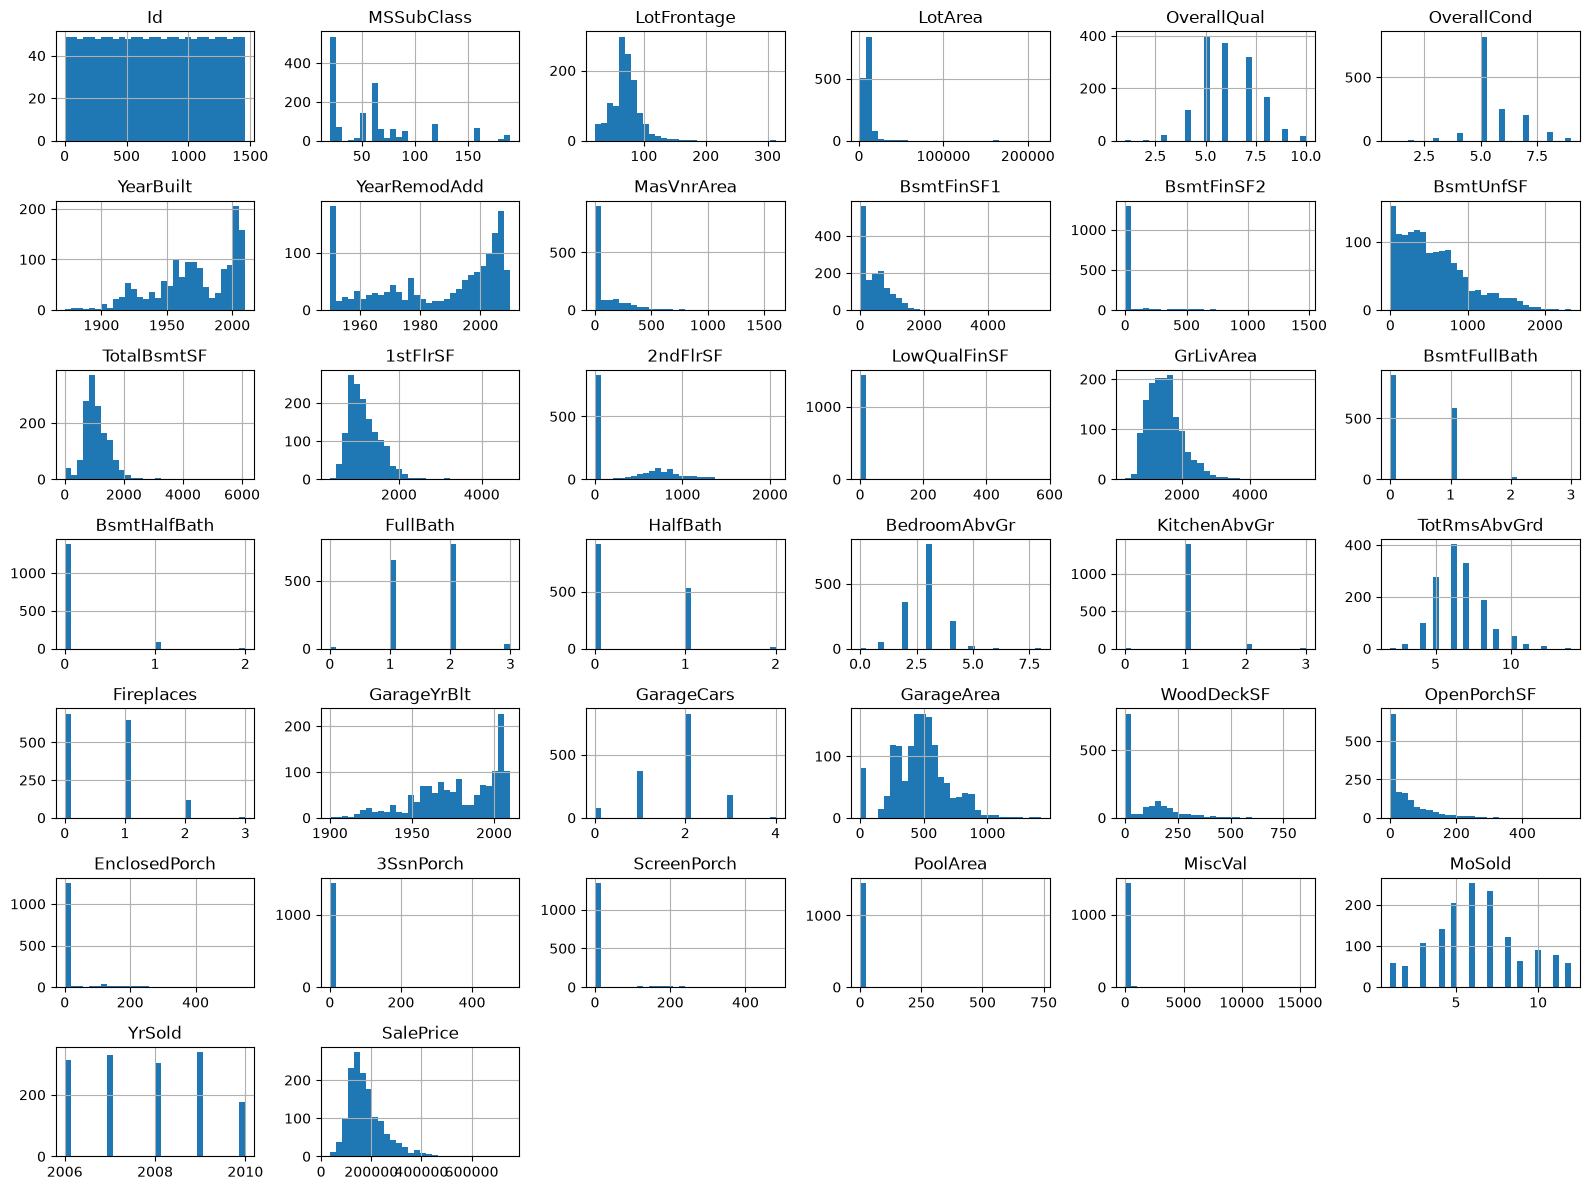

In [7]:
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols].hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

## Correlaciones

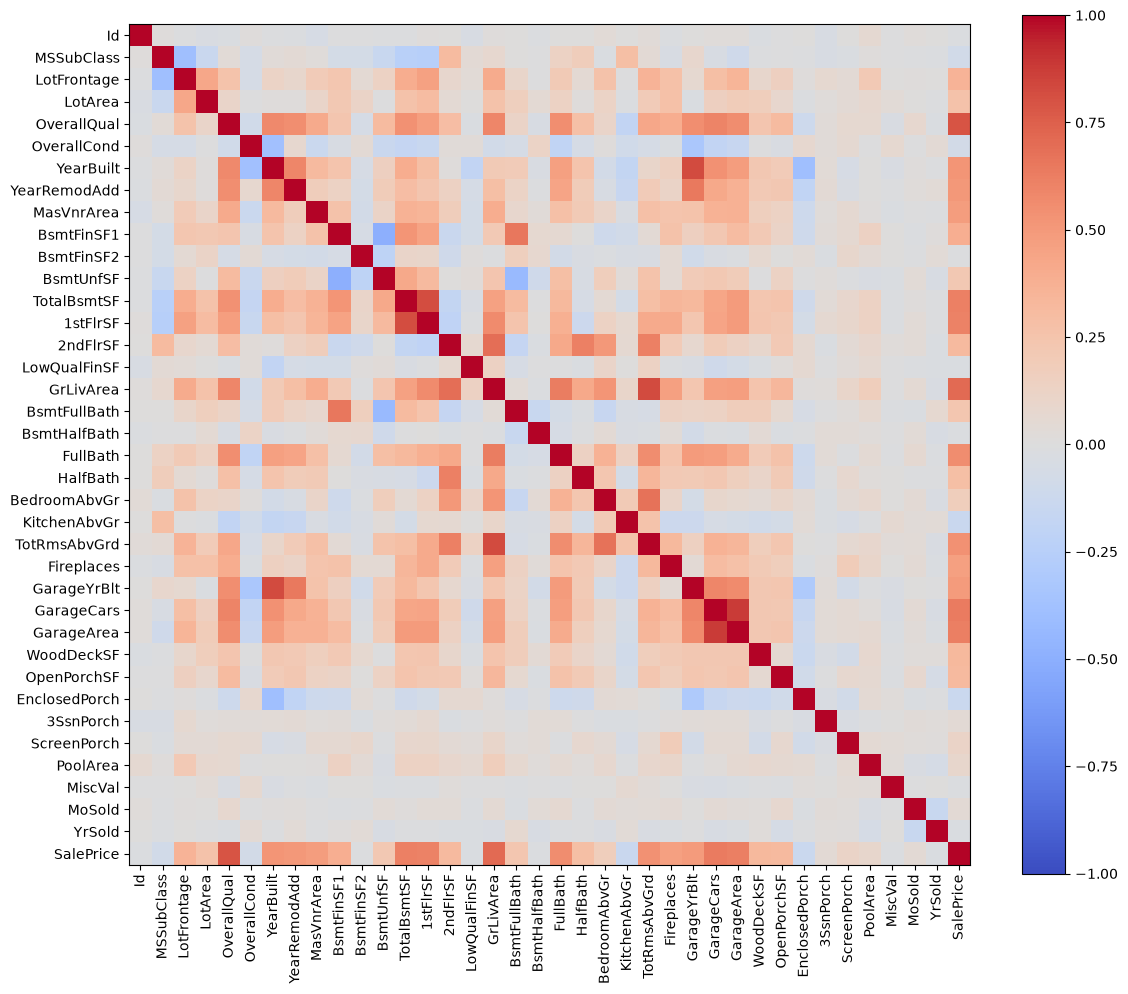

In [8]:
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=90)
ax.set_yticks(range(len(num_cols)), num_cols)
fig.colorbar(im)
plt.tight_layout()
plt.show()

## Variables discretas y continuas

Separa las variables numéricas en dos grupos: **discretas** (15 valores únicos o menos, como `OverallQual` o `GarageCars`) y **continuas** (el resto). `PoolArea` se deja como continua: tiene pocos valores únicos porque casi ninguna casa tiene piscina, pero es un área.

In [ ]:
target = "SalePrice"
features = [col for col in num_cols if col not in ("Id", target)]

max_valores_discretos = 15
excepciones_continuas = ["PoolArea"]

n_unicos = df[features].nunique()
discretas = [
    col for col in features
    if n_unicos[col] <= max_valores_discretos and col not in excepciones_continuas
]
continuas = [col for col in features if col not in discretas]

print(f"Discretas ({len(discretas)}): {discretas}")
print(f"Continuas ({len(continuas)}): {continuas}")

## Variables continuas vs SalePrice

Dibuja un scatter plot de cada variable continua contra `SalePrice`, con su correlación en el título, y muestra las correlaciones ordenadas de mayor a menor.

In [ ]:
n_cols = 4
n_rows = int(np.ceil(len(continuas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

correlaciones_continuas = {}
for ax, col in zip(axes, continuas):
    corr_target = df[col].corr(df[target])
    correlaciones_continuas[col] = corr_target
    ax.scatter(df[col], df[target], alpha=0.4, s=10)
    ax.set_title(f"{col} (corr = {corr_target:.2f})")
    ax.set_xlabel(col)
    ax.set_ylabel(target)

# Oculta los ejes sobrantes de la cuadrícula
for ax in axes[len(continuas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

corr_continuas_df = (
    pd.DataFrame.from_dict(correlaciones_continuas, orient="index", columns=["correlacion"])
    .sort_values("correlacion", ascending=False)
)
corr_continuas_df

## Variables discretas vs SalePrice

Dibuja un boxplot de `SalePrice` por cada valor de las variables discretas y encima los puntos individuales (con algo de dispersión horizontal), para ver cuántas casas hay en cada categoría. El título incluye la correlación con `SalePrice`.

In [ ]:
n_cols = 3
n_rows = int(np.ceil(len(discretas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

correlaciones_discretas = {}
for ax, col in zip(axes, discretas):
    corr_target = df[col].corr(df[target])
    correlaciones_discretas[col] = corr_target
    # Los atípicos no se dibujan en el boxplot porque el stripplot ya muestra todos los puntos
    sns.boxplot(data=df, x=col, y=target, ax=ax, color="lightsteelblue", showfliers=False)
    sns.stripplot(data=df, x=col, y=target, ax=ax, color="black", alpha=0.3, size=2.5, jitter=0.25)
    ax.set_title(f"{col} (corr = {corr_target:.2f})")

# Oculta los ejes sobrantes de la cuadrícula
for ax in axes[len(discretas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

corr_discretas_df = (
    pd.DataFrame.from_dict(correlaciones_discretas, orient="index", columns=["correlacion"])
    .sort_values("correlacion", ascending=False)
)
corr_discretas_df

## Variables categóricas vs SalePrice

Dibuja un boxplot de `SalePrice` por cada categoría de las variables categóricas, con los puntos individuales encima. Las categorías se ordenan por su mediana de precio, y los valores faltantes se agrupan como `"NA"`, porque en este dataset suelen significar que la casa no tiene ese elemento (por ejemplo, sin piscina o sin callejón).

El título de cada gráfica muestra la **razón de correlación η (eta)**, que mide qué tanto de la variación de `SalePrice` se explica por la categoría. Va de 0 (las categorías no distinguen precios) a 1 (la categoría determina el precio). Al final se muestra un DataFrame con η ordenada de mayor a menor.

In [ ]:
def razon_correlacion(categorias, valores):
    """Razón de correlación η entre una variable categórica y una numérica."""
    media_global = valores.mean()
    grupos = valores.groupby(categorias)
    ss_entre = (grupos.count() * (grupos.mean() - media_global) ** 2).sum()
    ss_total = ((valores - media_global) ** 2).sum()
    return np.sqrt(ss_entre / ss_total)


cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()
df_cat = df[cat_cols].fillna("NA")

n_cols = 3
n_rows = int(np.ceil(len(cat_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

eta_categoricas = {}
for ax, col in zip(axes, cat_cols):
    eta = razon_correlacion(df_cat[col], df[target])
    eta_categoricas[col] = eta
    orden = df[target].groupby(df_cat[col]).median().sort_values().index
    # Los atípicos no se dibujan en el boxplot porque el stripplot ya muestra todos los puntos
    sns.boxplot(x=df_cat[col], y=df[target], order=orden, ax=ax, color="lightsteelblue", showfliers=False)
    sns.stripplot(x=df_cat[col], y=df[target], order=orden, ax=ax, color="black", alpha=0.3, size=2.5, jitter=0.25)
    ax.set_title(f"{col} (η = {eta:.2f})")
    ax.tick_params(axis="x", rotation=45)

# Oculta los ejes sobrantes de la cuadrícula
for ax in axes[len(cat_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

eta_categoricas_df = (
    pd.DataFrame.from_dict(eta_categoricas, orient="index", columns=["eta"])
    .assign(n_categorias=df_cat.nunique())
    .sort_values("eta", ascending=False)
)
eta_categoricas_df

## Selección de features

Selecciona las 10 mejores variables de cada grupo según su métrica de relación con `SalePrice`: correlación de Pearson para continuas y discretas (en valor absoluto, porque una correlación negativa fuerte también es útil para predecir) y razón de correlación η para las categóricas. Estas serán las features para construir el modelo.

In [13]:
top_n = 10

top_continuas = corr_continuas_df["correlacion"].abs().nlargest(top_n).index.tolist()
top_discretas = corr_discretas_df["correlacion"].abs().nlargest(top_n).index.tolist()
top_categoricas = eta_categoricas_df["eta"].nlargest(top_n).index.tolist()

features_modelo = top_continuas + top_discretas + top_categoricas

print(f"top_continuas = {top_continuas}")
print(f"top_discretas = {top_discretas}")
print(f"top_categoricas = {top_categoricas}")
print(f"\nTotal de features: {len(features_modelo)}")

top_continuas = ['GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'LotFrontage']
top_discretas = ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'HalfBath', 'BsmtFullBath', 'BedroomAbvGr', 'KitchenAbvGr', 'MSSubClass']
top_categoricas = ['Neighborhood', 'ExterQual', 'BsmtQual', 'KitchenQual', 'GarageFinish', 'FireplaceQu', 'Foundation', 'GarageType', 'BsmtFinType1', 'HeatingQC']

Total de features: 30
